# **Arena**

## **Section 1: Setting directory and preparing the dataset**

In [ ]:
%%capture
!pip install torchmetrics
!pip install pkbar
!pip install calflops
!pip install torchinfo
!pip install grad-cam

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Drive Directory**

In [ ]:
import os
import zipfile
import json
import pandas as pd
import numpy as np
import random as rd
import shutil
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torchinfo import summary
import torchvision
from torchvision.transforms import v2, InterpolationMode
import timm
import calflops
from functools import partial

In [ ]:
drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
dataset_name = 'MushroomA'
dataset_drive_dir = f'{drive_dir}/data/{dataset_name}'

modify_type = 'C3'
model_name_path = f'convnext_tiny_modify_{modify_type}_224_r1_v1' # เปลี่ยนเสมอ
model_name = 'ConvNeXt-Tiny' # เปลี่ยนเสมอ

sigle_model_title = f'{model_name} Modify-{modify_type} on {dataset_name} Dataset'
ensemble_model_title = f'{model_name} Modify-{modify_type} Ensemble on {dataset_name} Dataset'
model_dir = os.path.join(drive_dir, f'myModelWeights/{dataset_name}', f"{model_name_path}_{dataset_name}")
model_ensem_dir = f'{model_dir}/ensemble'
model_summary_dir = f'{model_dir}/summary'

os.makedirs(model_dir, exist_ok=True)
font_dir = f'{drive_dir}/assets/fonts'

os.chdir(f'{drive_dir}')
print(f'Current directory: {os.getcwd()}')

Current directory: /content/drive/MyDrive/projectMushroom


**Runtime Directory**

In [ ]:
import src.reproducibility as reproducibility
import src.utils as utils
import src.datasets as datasets
import src.train as train
import src.test as test
import src.visualization as visualization
import src.gradCam as gradCam
import models.models as models

visualization.matplotlib_font(font_dir=font_dir, prefer_name='Times-Roman')
def callbacks_fn(n_fold, fold_dir):
    checkpoint_path = f'{fold_dir}/{model_name_path}_{dataset_name}_best_weight.pth'
    return [utils.ModelCheckpoint(save_path=checkpoint_path, monitor=train.train_config['monitor'], mode=train.train_config['monitor_mode'])]

In [ ]:
runtime_dir = '/content'
dataset_dir = f'{runtime_dir}/{dataset_name}'
os.makedirs(dataset_dir, exist_ok=True)

print(f'PyTorch version: {torch.__version__}')
print(f'Torchvision version: {torchvision.__version__}')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on {device}.')
!python3 --version
!nvidia-smi

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
Running on cuda.
Python 3.12.12
Sat Mar 21 07:29:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   39C    P8             13W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         | 

**Load data from G-Drive**

In [ ]:
with zipfile.ZipFile(f'{dataset_drive_dir}/{dataset_name}_SPLIT.zip', 'r') as zip_ref:
    zip_ref.extractall(dataset_dir)

remain_classes = set(os.listdir(f'{dataset_dir}/remain'))
test_classes = set(os.listdir(f'{dataset_dir}/test'))
unique_classes = remain_classes.union(test_classes)
NUM_CLASSES = len(unique_classes)
print(f'Number of classes: {NUM_CLASSES}')
print(f'Dataset has been extracted to {dataset_dir}')

Number of classes: 9
Dataset has been extracted to /content/MushroomA


## **Section 2: Define model architecture**

In [ ]:
model_fn = partial(
    models.build_modify_convnext,
    model_name=model_name,
    num_classes=NUM_CLASSES,
    device=device,
    target_stages=[0,1,2,3],
    freeze_backbone=False,
    modify_type=modify_type
)
model = model_fn()

criterion = nn.CrossEntropyLoss()
optimizer_fn = lambda m : optim.AdamW(m.parameters(), lr=train.train_config['base_lr'], weight_decay=train.train_config['weight_decay'])
scheduler_fn = partial(optim.lr_scheduler.CosineAnnealingLR, T_max=train.train_config['max_epochs'])

model_config = models.get_transform_config(model)
summary(model, (1,) + model_config['input_size'], device=device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Layer (type:depth-idx)                                  Output Shape              Param #
ConvNeXt                                                [1, 9]                    --
├─Sequential: 1-1                                       [1, 96, 56, 56]           --
│    └─Conv2d: 2-1                                      [1, 96, 56, 56]           4,704
│    └─LayerNorm2d: 2-2                                 [1, 96, 56, 56]           192
├─Sequential: 1-2                                       [1, 768, 7, 7]            --
│    └─ConvNeXtStage: 2-3                               [1, 96, 56, 56]           --
│    │    └─Identity: 3-1                               [1, 96, 56, 56]           --
│    │    └─Sequential: 3-2                             [1, 96, 56, 56]           252,048
│    └─ConvNeXtStage: 2-4                               [1, 192, 28, 28]          --
│    │    └─Sequential: 3-3                             [1, 192, 28, 28]          74,112
│    │    └─Sequential: 3-4                    

## **Section 3: Preparing the dataset**

**Configuration for training**

In [ ]:
img_size = model_config['img_size']
resize_size = int(img_size[0] / model_config['crop_pct'])
interp_mode = getattr(InterpolationMode, model_config['interpolation'].upper())
num_workers = min(4, os.cpu_count())

print(f'Image size: {img_size}')
print(f'Resize size: {resize_size}')
print(f'Interpolation mode: {interp_mode}')
print(f'Number of workers: {num_workers}')

reproducibility.global_seed(seed=train.train_config['seed'])
reproducibility.training_seed(seed=train.train_config['seed'])
g = reproducibility.get_generator(seed=train.train_config['seed'])

Image size: (224, 224)
Resize size: 256
Interpolation mode: InterpolationMode.BICUBIC
Number of workers: 4
Global Seed set to: 42
Training Seed set to: 42


In [ ]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(img_size, scale=(0.08, 1.0), interpolation=interp_mode),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandAugment(num_ops=2, magnitude=6, interpolation=interp_mode),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std']),
    v2.RandomErasing(p=0.5, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=False)
])

transform = v2.Compose([
    v2.Resize(resize_size, interpolation=interp_mode, max_size=None, antialias=True),
    v2.CenterCrop(img_size),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std'])
])

dataloader_kwargs = {
    'batch_size': train.train_config['batch_size'],
    'num_workers': num_workers,
    'worker_init_fn': reproducibility.seed_worker,
    'generator': g,
    'pin_memory': True
}

datasets = datasets.Datasets(
    dataset_dir=dataset_dir,
    train_transform=train_transform,
    transform=transform,
    dataloader_kwargs=dataloader_kwargs,
)

datasets.print_summary()
test_loader = datasets.get_test_loader()

--------------------------------------------------
Dataset Summary
--------------------------------------------------
Class names       : ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']
Class to Index    : {'Agaricus': 0, 'Amanita': 1, 'Boletus': 2, 'Cortinarius': 3, 'Entoloma': 4, 'Hygrocybe': 5, 'Lactarius': 6, 'Russula': 7, 'Suillus': 8}
Index to Class    : {0: 'Agaricus', 1: 'Amanita', 2: 'Boletus', 3: 'Cortinarius', 4: 'Entoloma', 5: 'Hygrocybe', 6: 'Lactarius', 7: 'Russula', 8: 'Suillus'}
Total remain data : 5302
Total test data   : 1326
--------------------------------------------------


## **Section 4: Training the model**

In [ ]:
trainer = train.KFoldTrainer(
    n_splits=train.train_config['n_folds'],
    shuffle=True,
    random_state=train.train_config['seed'],
    model_name=model_name_path,
    dataset_name=dataset_name,
    base_dir=model_dir,
    first_metric=train.train_config['first_metric'],
    first_metric_mode=train.train_config['first_metric_mode'],
    secondary_metric=train.train_config['secondary_metric'],
    secondary_metric_mode=train.train_config['secondary_metric_mode'],
    device=device,
    criterion=criterion,
    n_classes=NUM_CLASSES,
    task=train.train_config['task'],
    average=train.train_config['average'],
    max_grad_norm=0.0
)

[Logs] Setup directories at '/content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA' successfully.


In [ ]:
fold_histories = trainer.fit_kfold(
    train_dataset=datasets.train_dataset,
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    model_fn=model_fn,
    optimizer_fn=optimizer_fn,
    epochs=train.train_config['max_epochs'],
    dataloader_kwargs=dataloader_kwargs,
    callbacks_fn=callbacks_fn,
    scheduler_fn=scheduler_fn
)

Starting Stratified 5-Fold Cross Validation

--------------------------------------------- FOLD 1/5 ---------------------------------------------
Epoch: 1/30
133/133 [==============================] - 47s 352ms/step - loss: 1.4542 - lr: 1.0000e-04 - accuracy: 0.5228 - f1: 0.3924 - precision: 0.5642 - recall: 0.3852
Epoch 1/30 | val_loss: 0.7414 - val_accuracy: 0.7691 - val_f1: 0.6791 - val_precision: 0.8207 - val_recall: 0.6703
[Logs] Epoch: 1 val_accuracy improved from -inf to 0.7691, saving model to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/fold_1/convnext_tiny_modify_C3_224_r1_v1_MushroomA_best_weight.pth
Epoch: 2/30
133/133 [==============================] - 39s 293ms/step - loss: 0.6544 - lr: 9.9726e-05 - accuracy: 0.7890 - f1: 0.7615 - precision: 0.7863 - recall: 0.7446
Epoch 2/30 | val_loss: 0.3611 - val_accuracy: 0.8841 - val_f1: 0.8623 - val_precision: 0.8906 - val_recall: 0.8466
[Logs] Epoch: 2 val_accuracy imp

## **Section 5: Individual model performance**

In [ ]:
y_true = test.get_true_label(test_loader, is_onehot=False)

### **Learning curve**

#### **Individual**

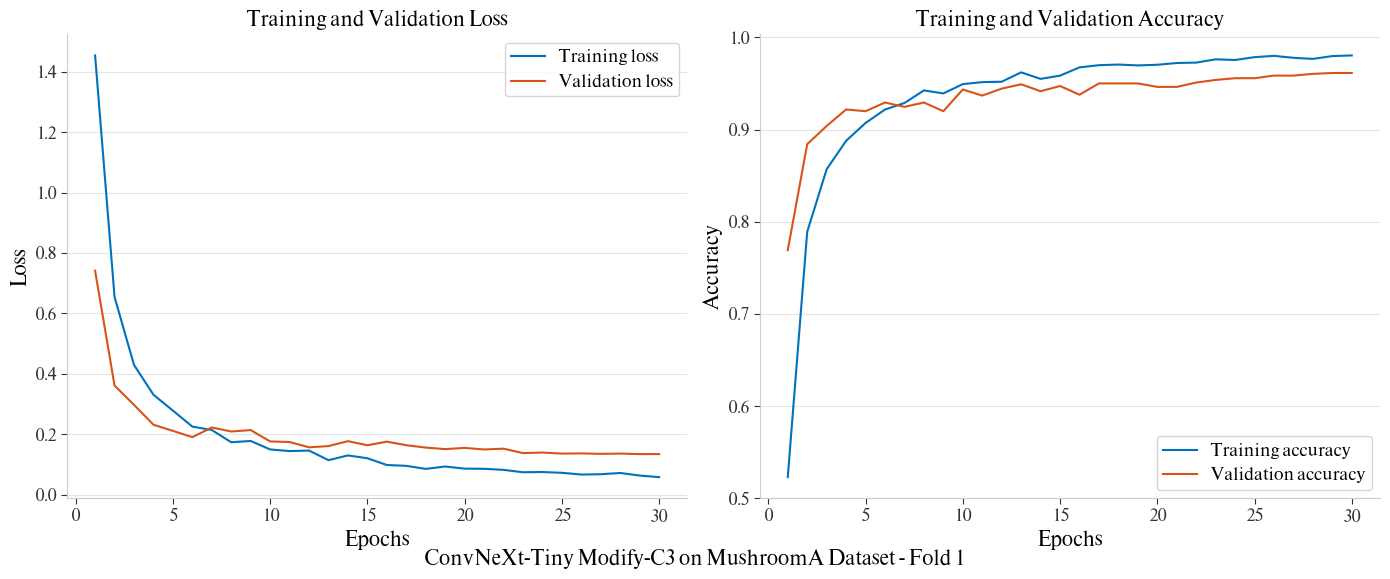

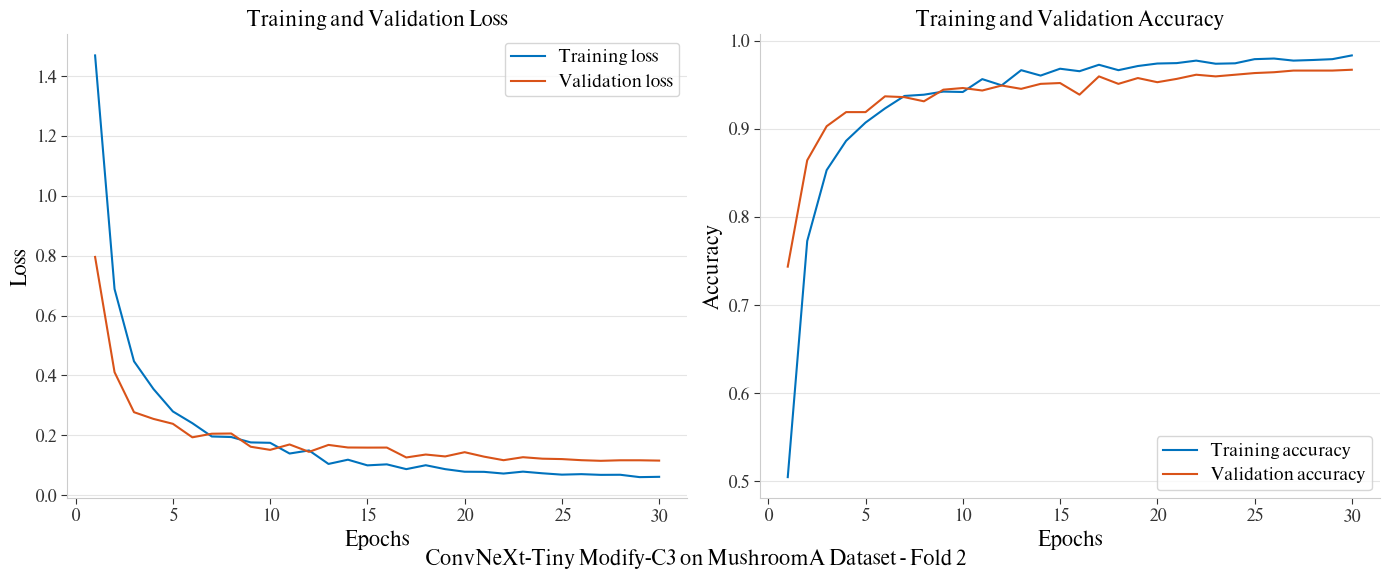

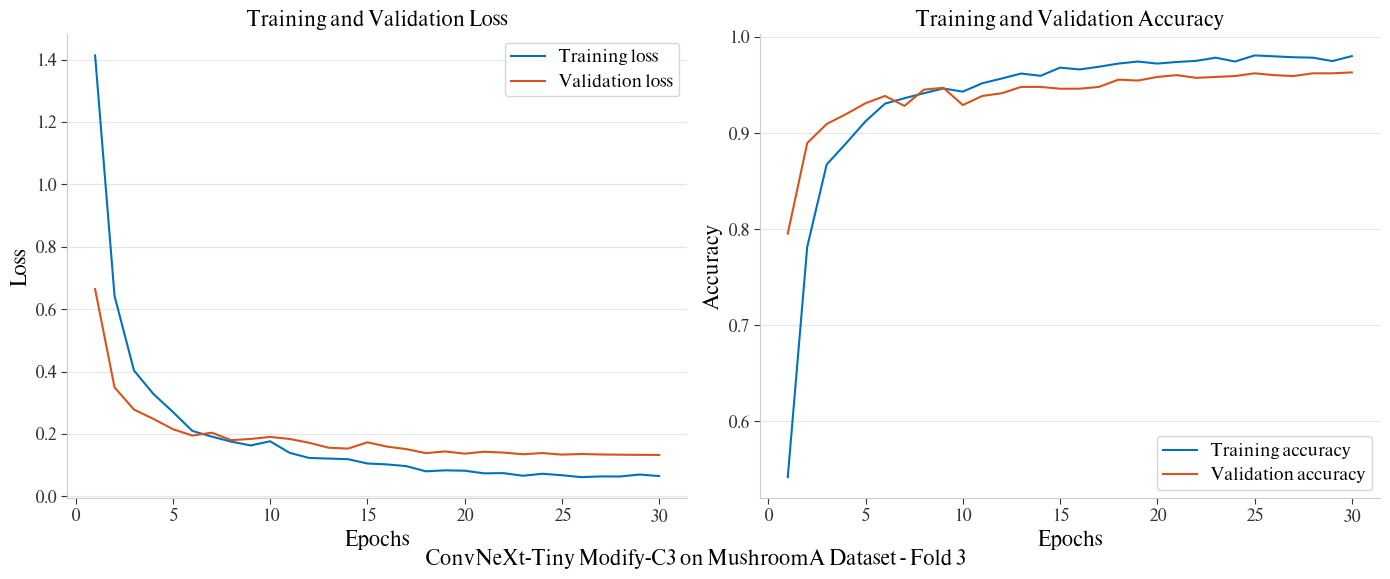

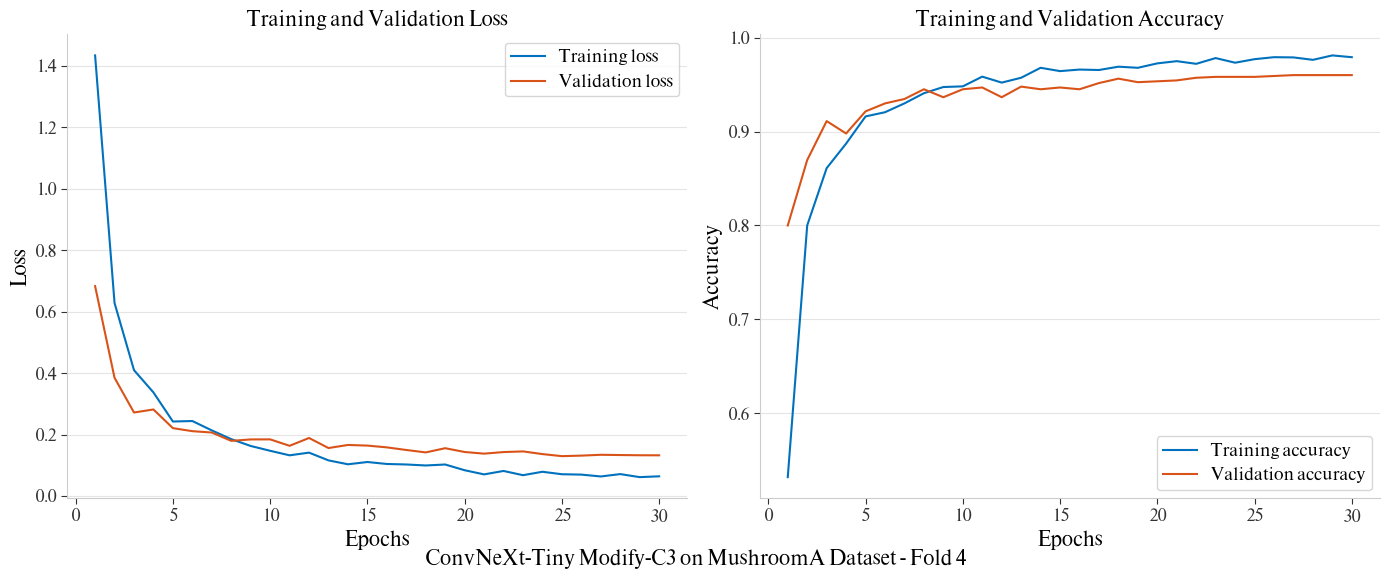

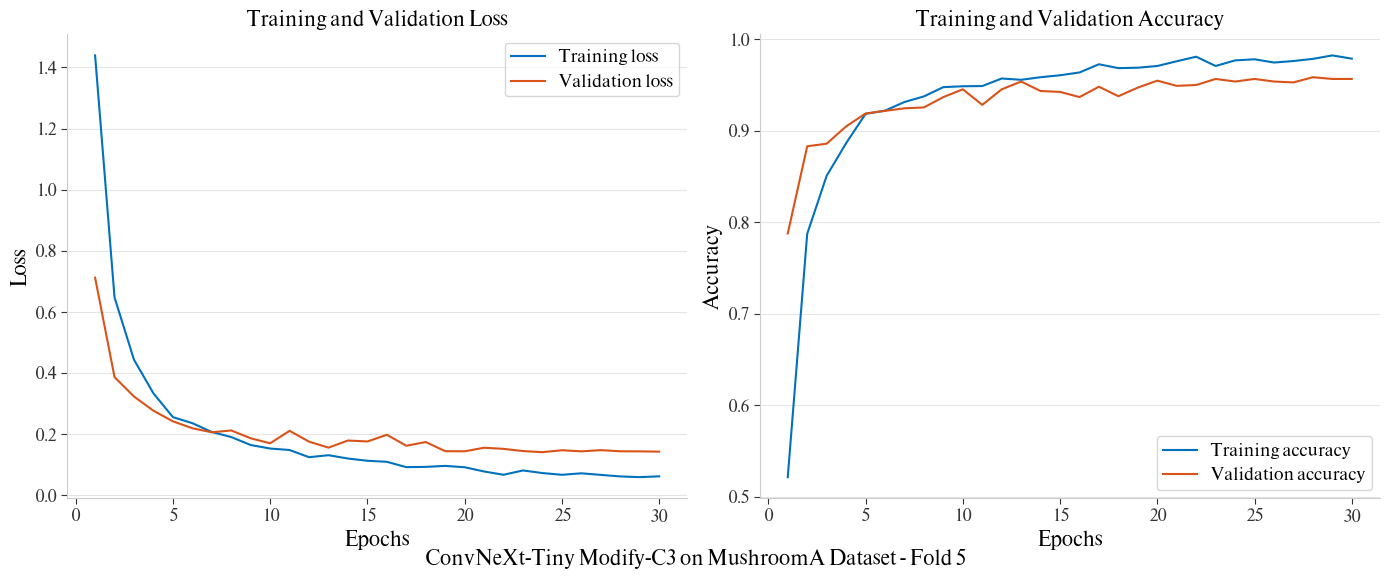

In [ ]:
for fold_key, history in fold_histories.items():
    fold_num = fold_key.split('_')[1]
    fold_dir = f"{trainer.base_dir}/fold_{fold_num}"

    visualization.plot_lr_curve(
        history=history,
        figsize=(14, 6),
        fontsize=14,
        title=f"{sigle_model_title} - Fold {fold_num}",
        save_path=fold_dir
    )

    print('\n')

#### **Overall**

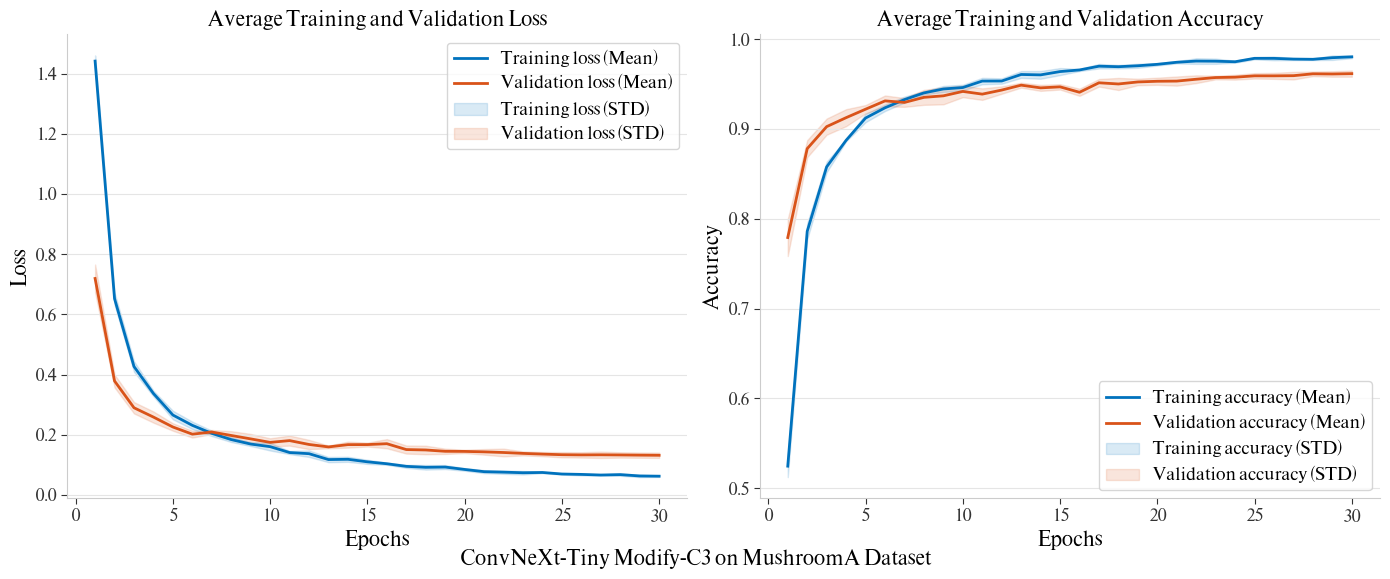

In [ ]:
visualization.plot_cv_summary_curve(
    histories=list(fold_histories.values()),
    figsize=(14, 6),
    fontsize=14,
    title=sigle_model_title,
    save_path=model_ensem_dir
)

### **On validation set**

In [ ]:
individual_validate_perf_df = trainer.evaluate_kfold(
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    dataloader_kwargs=dataloader_kwargs,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type']
)

Evaluating 5-Fold Models on their respective Validation Sets (BEST weights)



[*] Evaluating Fold 1/5 on its Validation Set...
34/34 [==============================] - 4s 104ms/step - loss: 0.1341 - accuracy: 0.9614 - f1: 0.9614 - precision: 0.9580 - recall: 0.9652
[*] Evaluating Fold 2/5 on its Validation Set...
34/34 [==============================] - 4s 107ms/step - loss: 0.1155 - accuracy: 0.9670 - f1: 0.9647 - precision: 0.9689 - recall: 0.9613
[*] Evaluating Fold 3/5 on its Validation Set...
34/34 [==============================] - 4s 105ms/step - loss: 0.1330 - accuracy: 0.9632 - f1: 0.9538 - precision: 0.9553 - recall: 0.9527
[*] Evaluating Fold 4/5 on its Validation Set...
34/34 [==============================] - 4s 105ms/step - loss: 0.1342 - accuracy: 0.9604 - f1: 0.9560 - precision: 0.9641 - recall: 0.9493
[*] Evaluating Fold 5/5 on its Validation Set...
34/34 [==============================] - 4s 105ms/step - loss: 0.1440 - accuracy: 0.9585 - f1: 0.9544 - precision: 0.9640 - recall: 0.9460

-----------------------------------------------------------

### **On test set**

In [ ]:
ensemble_probs, timing_report = trainer.predict_kfold(
    dataloader=test_loader,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type'],
    timer_report_dict=True,
    verbose=1
)

Ensemble Prediction using 5-Fold Models (BEST weights)

[*] Running inference for Fold 1/5...
42/42 [==============================] - 7s 156ms/step

[Inference Report] Latency: 109.01 ms/batch | Throughput: 289.62 samples/sec
    -> Saved fold 1 timing report to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/fold_1/fold_1_infer_timing_report.csv
    -> Saved fold 1 predictions to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/fold_1/fold_1_test_probs_best_weight.csv
[*] Running inference for Fold 2/5...
42/42 [==============================] - 4s 105ms/step

[Inference Report] Latency: 58.23 ms/batch | Throughput: 542.20 samples/sec
    -> Saved fold 2 timing report to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/fold_2/fold_2_infer_timing_report.csv
    -> Saved fold 2 predictions to /content/drive/MyD

In [ ]:
individual_test_perf_df = test.evaluate_preds_kfold(
    base_dir=model_dir,
    n_splits=train.train_config['n_folds'],
    y_true=y_true,
    weight_type=train.train_config['weight_type'],
    task=train.train_config['task'],
    average=train.train_config['average'],
)

[*] Fold 1/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 2/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 3/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 4/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro
[*] Fold 5/5 | Shape: (1326, 9)
[*] Task Type: Multiclass | Average: macro

----------------------------------------------------------------------------------------------------
K-Fold Test Set Evaluation Results (Individual Models):
  Fold     loss  accuracy       f1  precision   recall
Fold 1 0.126807  0.965309 0.960690   0.960089 0.961475
Fold 2 0.140667  0.952489 0.947445   0.947937 0.947234
Fold 3 0.146698  0.957768 0.955132   0.957018 0.953523
Fold 4 0.158395  0.950226 0.947771   0.955714 0.940649
Fold 5 0.149691  0.953997 0.952032   0.955666 0.948635
  Mean 0.144451  0.955958 0.952614   0.955285 0.950303
   STD 0.011753  0.005905 0.005524   0.004484 0.007755
---------------------------

## **Section 6: Ensemble model performance**

### **On test set**

In [ ]:
y_pred, metrics = test.evaluate_preds(
    y_true=y_true,
    y_probs=ensemble_probs,
    task=train.train_config['task'],
    average=train.train_config['average'],
    save_path=f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv'
)

[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/ensemble/ensem_test_perf_best_weight.csv


### **Classification report**

In [ ]:
report = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name)

report_dict = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(f'{model_ensem_dir}/ensem_classification_report.csv')

print('Classification Report on Ensemble')
print('=' * 100)
print(report)

Classification Report on Ensemble
              precision    recall  f1-score   support

    Agaricus     0.9571    0.9571    0.9571        70
     Amanita     0.9728    0.9533    0.9630       150
     Boletus     0.9860    0.9906    0.9883       213
 Cortinarius     0.9701    0.9701    0.9701       167
    Entoloma     0.9855    0.9315    0.9577        73
   Hygrocybe     0.9841    0.9841    0.9841        63
   Lactarius     0.9484    0.9800    0.9639       300
     Russula     0.9733    0.9605    0.9669       228
     Suillus     0.9508    0.9355    0.9431        62

    accuracy                         0.9683      1326
   macro avg     0.9698    0.9625    0.9660      1326
weighted avg     0.9685    0.9683    0.9683      1326



### **Correct predictions**

In [ ]:
df_correct, df_incorrect = test.pred_records(
    y_true=y_true,
    y_pred=y_pred,
    y_probs=ensemble_probs,
    filepaths=[path for path, _ in test_loader.dataset.samples],
    idx_to_class=datasets.idx_to_class,
    save_dir=f'{model_ensem_dir}',
    prefix='ensem'
)

In [ ]:
df_correct

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomA/test/Agaricus/001_2jP9N_ipA...,Agaricus,Agaricus,0,0,0.973732
1,/content/MushroomA/test/Agaricus/016_qNYODERZE...,Agaricus,Agaricus,0,0,0.999384
2,/content/MushroomA/test/Agaricus/027_-CwuQDPSh...,Agaricus,Agaricus,0,0,0.975797
3,/content/MushroomA/test/Agaricus/028_-vDPakMKn...,Agaricus,Agaricus,0,0,0.995001
4,/content/MushroomA/test/Agaricus/042_qk77X1_g0...,Agaricus,Agaricus,0,0,0.999308
...,...,...,...,...,...,...
1279,/content/MushroomA/test/Suillus/291_JvaBBYqBgB...,Suillus,Suillus,8,8,0.949634
1280,/content/MushroomA/test/Suillus/297_XQdw8OtzxL...,Suillus,Suillus,8,8,0.991561
1281,/content/MushroomA/test/Suillus/308_KjxkhQlHYr...,Suillus,Suillus,8,8,0.915514
1282,/content/MushroomA/test/Suillus/311_MfqUejCCW5...,Suillus,Suillus,8,8,0.972741


### **Incorrect predictions**

In [ ]:
df_incorrect

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomA/test/Agaricus/320_ebYxJS43T...,Amanita,Agaricus,1,0,0.896455
1,/content/MushroomA/test/Agaricus/333_LwsnJQC9r...,Entoloma,Agaricus,4,0,0.917200
2,/content/MushroomA/test/Agaricus/354_VP-DWvLyI...,Amanita,Agaricus,1,0,0.918560
3,/content/MushroomA/test/Amanita/386_1CH7OWFK1z...,Russula,Amanita,7,1,0.571526
4,/content/MushroomA/test/Amanita/437_TI-chUFr6Z...,Hygrocybe,Amanita,5,1,0.475056
5,/content/MushroomA/test/Amanita/475_3-LU-M6jSU...,Russula,Amanita,7,1,0.995975
6,/content/MushroomA/test/Amanita/536_xGjRHkFDGS...,Agaricus,Amanita,0,1,0.285306
7,/content/MushroomA/test/Amanita/633_h1geqGA79w...,Lactarius,Amanita,6,1,0.664208
8,/content/MushroomA/test/Amanita/725_IybD3vqx0z...,Russula,Amanita,7,1,0.900351
9,/content/MushroomA/test/Amanita/770_052Nt-FjZI...,Cortinarius,Amanita,3,1,0.399623


### **Confusion matrix**

#### **without Normalize**

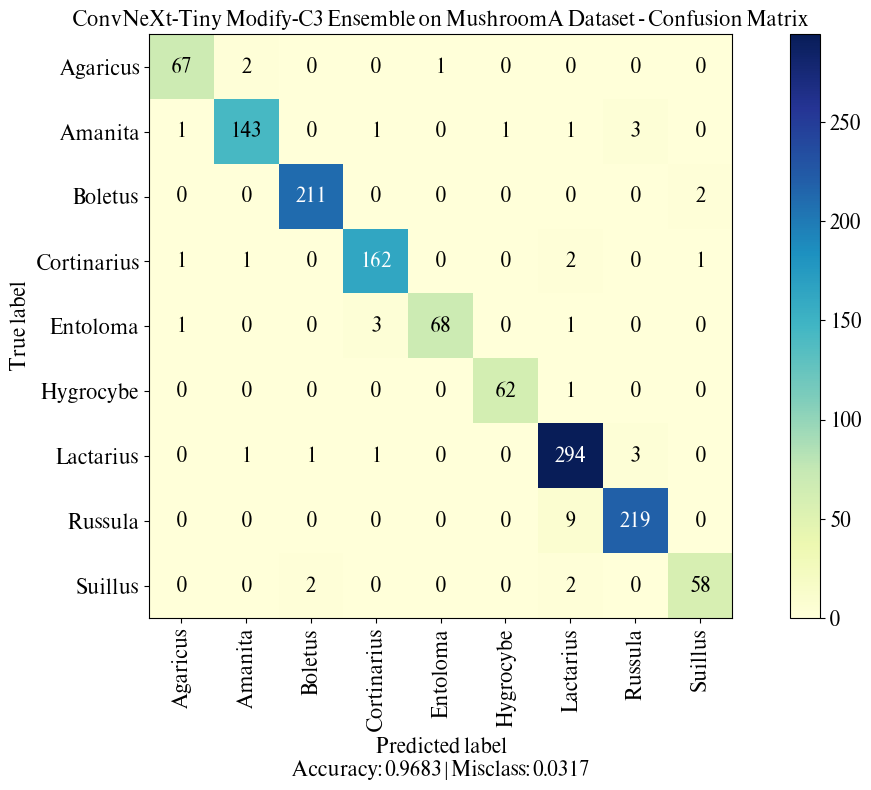

In [ ]:
cm = confusion_matrix(y_true, y_pred)
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=False,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 8),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

#### **with Normalize**

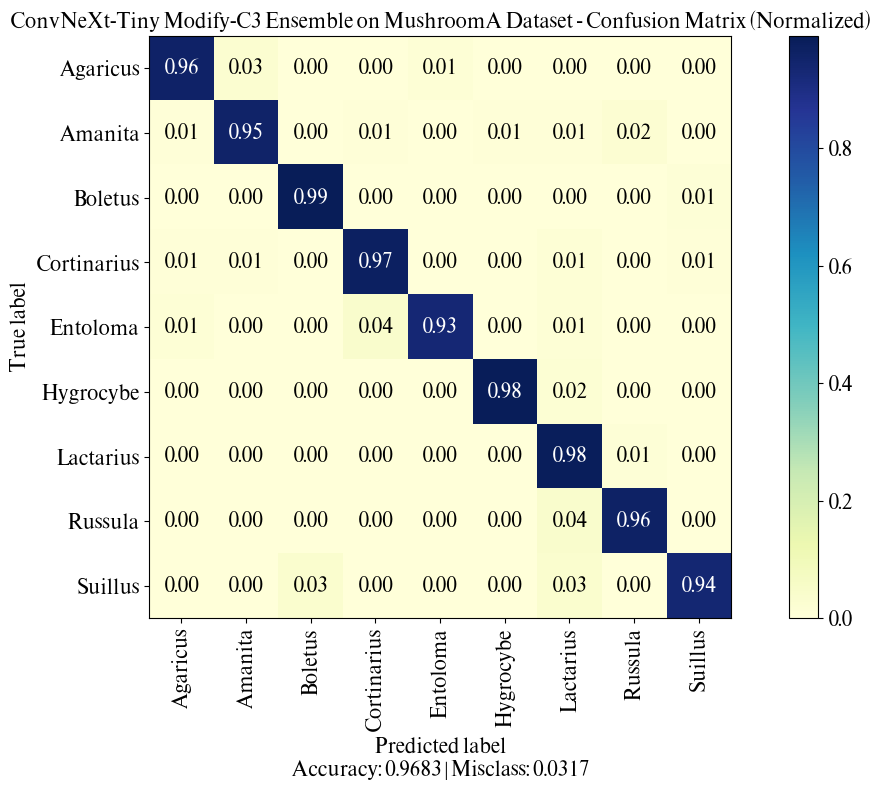

In [ ]:
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=True,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 8),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

### **ROC-AUC curve**

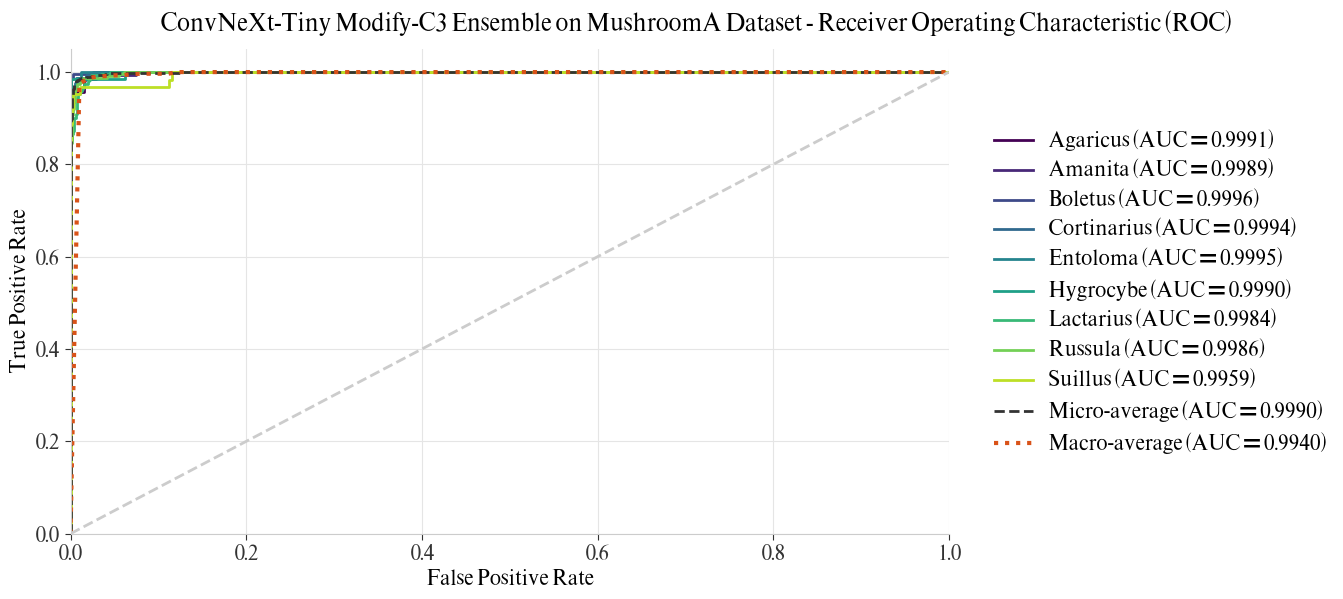

In [ ]:
visualization.plot_roc_auc_curve(
    y_true=y_true,
    y_pred_probs=ensemble_probs,
    class_names=datasets.classes_name,
    task=train.train_config['task'],
    legend_ncol=1,
    figsize=(14, 6),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

## **Section 7: Grad-CAM**

In [ ]:
best_model, best_fold_dir, best_fold_num = trainer.get_best_model_on_validate_set(model_fn=model_fn)
target_layers = [best_model.stages[-1].blocks[-1]]
print(target_layers)

[Logs] Retrieving Best Model from Fold 2
       Primary Metric: accuracy->0.9670 | Secondary: loss->0.1155 on Validation set.
[ConvNeXtBlockModify(
  (conv_dw): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (pre_attn): Identity()
  (mlp): MlpWithMiddleAttention(
    (fc1): Linear(in_features=768, out_features=3072, bias=True)
    (act): GELU()
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (middle_attn): Identity()
    (fc2): Linear(in_features=3072, out_features=768, bias=True)
    (drop2): Dropout(p=0.0, inplace=False)
  )
  (post_attn): CoordinateAttention(
    (conv1): Conv2d(768, 48, kernel_size=(1, 1), stride=(1, 1))
    (bn1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act): GELU(approximate='none')
    (conv_h): Conv2d(48, 768, kernel_size=(1, 1), stride=(1, 1))
    (conv_w): Conv2d(48, 768, kernel_size=(1, 1), stri

In [ ]:
unique_label = pd.read_csv(f'{dataset_drive_dir}/unique_label.csv')
unique_label

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomA/test/Entoloma/385_3iniw1mVk...,Entoloma,Entoloma,4,4,0.970201
1,/content/MushroomA/test/Boletus/0993_YMPWY3nZZ...,Boletus,Boletus,2,2,0.991539
2,/content/MushroomA/test/Lactarius/310_MVmkt2VW...,Lactarius,Lactarius,6,6,0.986088
3,/content/MushroomA/test/Amanita/290_8VTdQ2j5LL...,Amanita,Amanita,1,1,0.999764
4,/content/MushroomA/test/Russula/433_P89n7ud6bL...,Russula,Russula,7,7,0.999470
5,/content/MushroomA/test/Cortinarius/540_r5xzAI...,Cortinarius,Cortinarius,3,3,0.998794
6,/content/MushroomA/test/Agaricus/351_mHFbGn8oQ...,Agaricus,Agaricus,0,0,0.999605
7,/content/MushroomA/test/Hygrocybe/172_o-_VYiEs...,Hygrocybe,Hygrocybe,5,5,0.998320
8,/content/MushroomA/test/Suillus/231__NpqweN7Eq...,Suillus,Suillus,8,8,0.997972


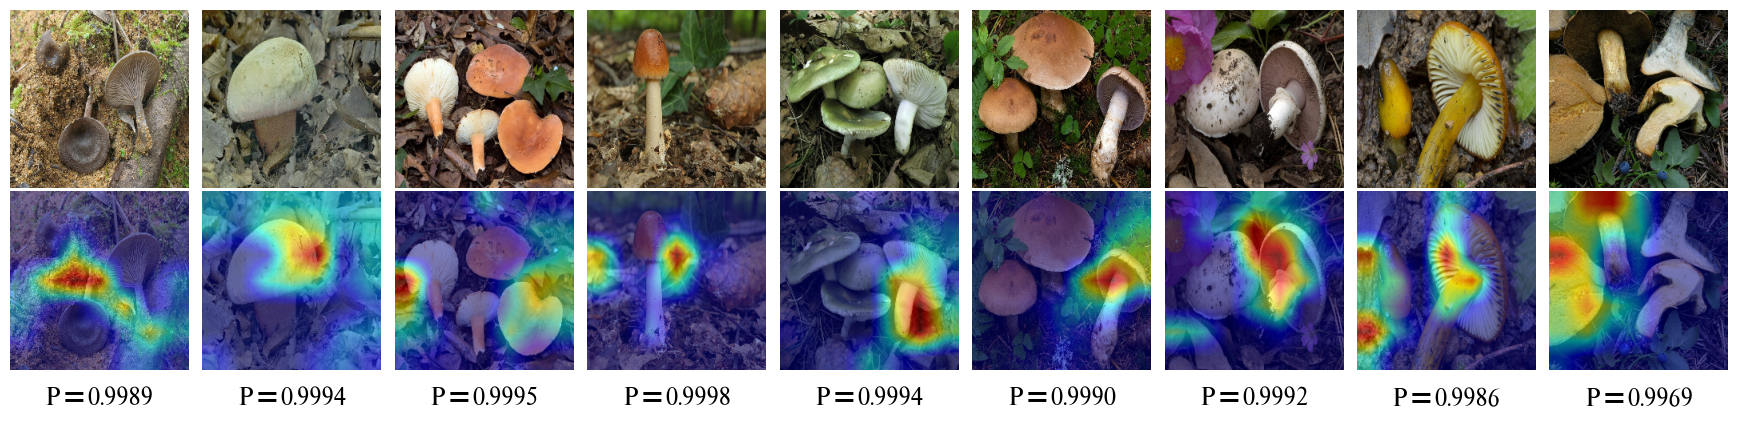

In [ ]:
gradCam.plot_grad_cam(
    model=best_model,
    target_layers=target_layers,
    df=unique_label,
    filepaths_col='Filepaths',
    true_label_col='True_Label',
    true_idx='True_Index',
    device=device,
    transform=transform,
    task=train.train_config['task'],
    reshape_transform=None,
    img_size=model_config['img_size'],
    img_base_size=2,
    row_one_title=False,
    fontsize=16,
    save_path=model_ensem_dir
)

## **Section 8: Summary**

##### **Performace on Validation Set (N Folds)**

In [ ]:
display(individual_validate_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.134142,0.961357,0.961415,0.958035,0.965195
Fold 2,0.115466,0.967012,0.964667,0.968921,0.961277
Fold 3,0.133034,0.963208,0.953845,0.955295,0.952655
Fold 4,0.134161,0.960377,0.956019,0.964096,0.949329
Fold 5,0.143966,0.958491,0.954368,0.963972,0.945958
Mean,0.132154,0.962089,0.958063,0.962064,0.954883
STD,0.010329,0.003237,0.004756,0.005405,0.008104


##### **Performace on Test Set (N Folds)**

In [ ]:
display(individual_test_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.126807,0.965309,0.960690,0.960089,0.961475
Fold 2,0.140667,0.952489,0.947445,0.947937,0.947234
Fold 3,0.146698,0.957768,0.955132,0.957018,0.953523
Fold 4,0.158395,0.950226,0.947771,0.955714,0.940649
Fold 5,0.149691,0.953997,0.952032,0.955666,0.948635
Mean,0.144451,0.955958,0.952614,0.955285,0.950303
STD,0.011753,0.005905,0.005524,0.004484,0.007755


##### **Performace on Test Set (Ensemble)**

In [ ]:
ensem_test_perf_df = pd.read_csv(f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv')
display(ensem_test_perf_df.style.hide(axis="index"))

loss,accuracy,f1,precision,recall
0.110425,0.968326,0.966027,0.969794,0.962532


#### **Model Info**

In [ ]:
flops, macs, params = calflops.calculate_flops(
    model=best_model,
    input_shape=(1,) + model_config['input_size'],
    output_precision=4,
    print_results=False
)

flops_val = float(flops.split()[0])
if 'MFLOPS' in flops:
    flops_val /= 1000.0
flops = f'{flops_val:.4f}'

macs_val = float(macs.split()[0])
if 'MMACs' in macs:
    macs_val /= 1000.0
macs = f'{macs_val:.4f}'

params_val = float(params.split()[0])
if 'K' in params:
    params_val /= 1000.0
elif 'B' in params:
    params_val *= 1000.0
params = f'{params_val:.4f}'

model_summary_report = {
    'Batch Size': [train.train_config['batch_size']],
    'Image Size': [f'{img_size[0]}\u00D7{img_size[1]}'],
    'GFLOPs': [flops],
    'GMACs': [macs],
    'Params (M)': [params],
    'Latency (ms/img)': timing_report['avg_single_model_latency_sample'],
    'Latency (ms/batch)': timing_report['avg_single_model_latency_batch'],
    'Throughput (img/s)': timing_report['avg_single_model_throughput'],
}

model_summary_df = pd.DataFrame(model_summary_report)
model_summary_df.to_csv(f'{model_summary_dir}/model_summary.csv', index=False)
display(model_summary_df.style.hide(axis="index"))

Batch Size,Image Size,GFLOPs,GMACs,Params (M),Latency (ms/img),Latency (ms/batch),Throughput (img/s)
32,224×224,8.9462,4.4589,28.0379,1.855103,58.568239,539.095310


## **Section 9: Addition**

##### **Preparation**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

add_drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
add_dataset_name = 'MushroomA'

def get_model_dir(model_name_path, weights_root='modelWeights', dataset_name=add_dataset_name):
    return os.path.join(add_drive_dir, f'{weights_root}/{dataset_name}', f'{model_name_path}_{dataset_name}')

# Model of this notebook
add_weights_root = 'myModelWeights'
modify_type = 'C3' # เปลี่ยนเสมอ
add_model_name_path = f'convnext_tiny_modify_{modify_type}_224_r1_v1'
add_model_name = f'ConvNeXt-Tiny Modify-{modify_type}'
add_model_dir = get_model_dir(add_model_name_path, weights_root=add_weights_root)

# McNemar's test: Baseline vs Proposed (Default proposed = model of this notebook)
mc_baseline_name = 'ConvNeXt-Tiny'
mc_baseline_model_dir = get_model_dir('convnext_tiny_224_r1_v1', weights_root='modelWeights')
mc_proposed_name = add_model_name
mc_proposed_model_dir = add_model_dir
mc_alpha = 0.05

add_config = {
    'n_folds': 5,
    'task': 'multiclass',
    'average': 'macro',
    'weight_type': 'best',
}

add_plot_kwargs = {
    'cmap': plt.cm.YlGnBu,
    'fontsize': 14,
}

In [3]:
os.chdir(add_drive_dir)
print(f'Current directory: {os.getcwd()}')
print(f'Model directory   : {add_model_dir}')
print(f'Baseline directory: {mc_baseline_model_dir}')
print(f'Proposed directory: {mc_proposed_model_dir}')

import src.visualization as visualization
import src.ensembleVoting as ensembleVoting
import src.mcnemarTest as mcnemarTest

visualization.matplotlib_font(font_dir=f'{add_drive_dir}/assets/fonts', prefer_name='Times-Roman')

Current directory: /content/drive/MyDrive/projectMushroom
Model directory   : /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA
Baseline directory: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v1_MushroomA
Proposed directory: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA


'OPTITimes-Roman'

##### **Compare voting strategies on test set**

[*] Loaded Fold 1/5 probabilities | Shape: (1326, 9)
[*] Loaded Fold 2/5 probabilities | Shape: (1326, 9)
[*] Loaded Fold 3/5 probabilities | Shape: (1326, 9)
[*] Loaded Fold 4/5 probabilities | Shape: (1326, 9)
[*] Loaded Fold 5/5 probabilities | Shape: (1326, 9)
[*] Recovered test order verified against /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/ensemble/ensem_test_probs_best_weight.csv
[*] Recovered 1326 test samples | 9 classes
[Logs] Saved Voting Weights to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/ensemble_addition/voting_weights_best_weight.csv

Voting Method: SOFT
[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/ensemble_addition/soft/soft_test_perf_best_weight.csv
              precision    recall  f1-score   support

    

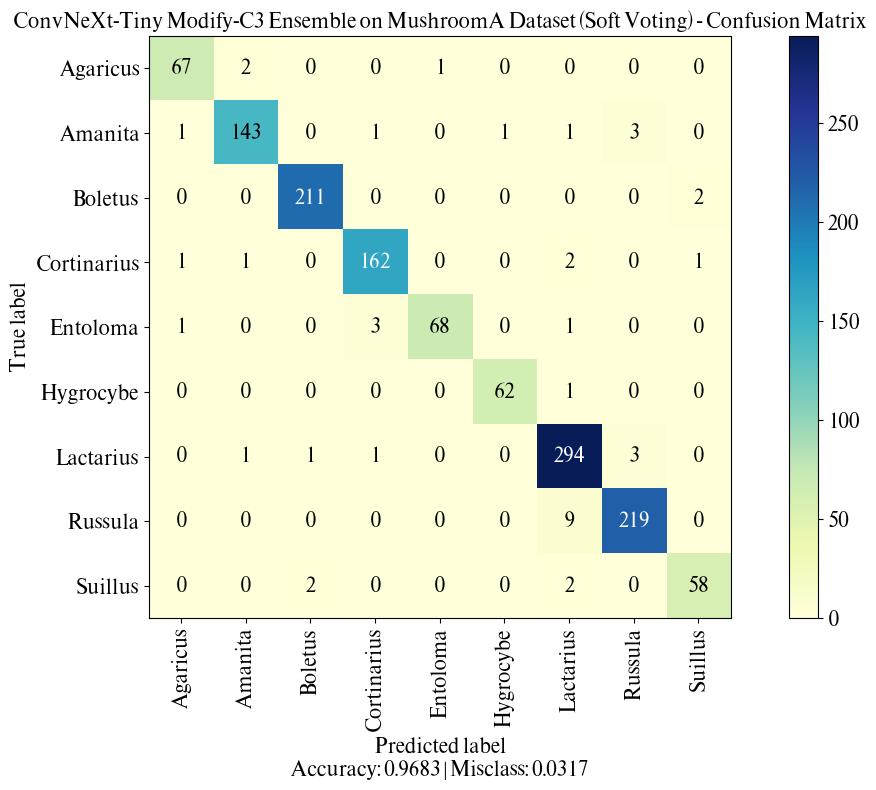

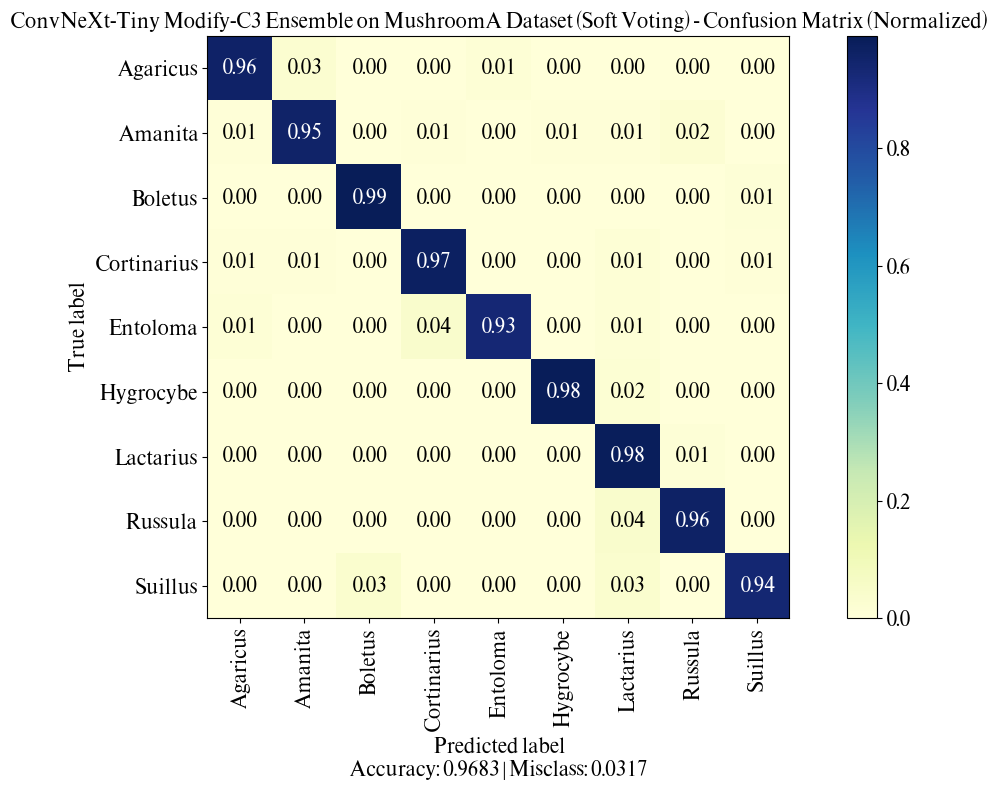

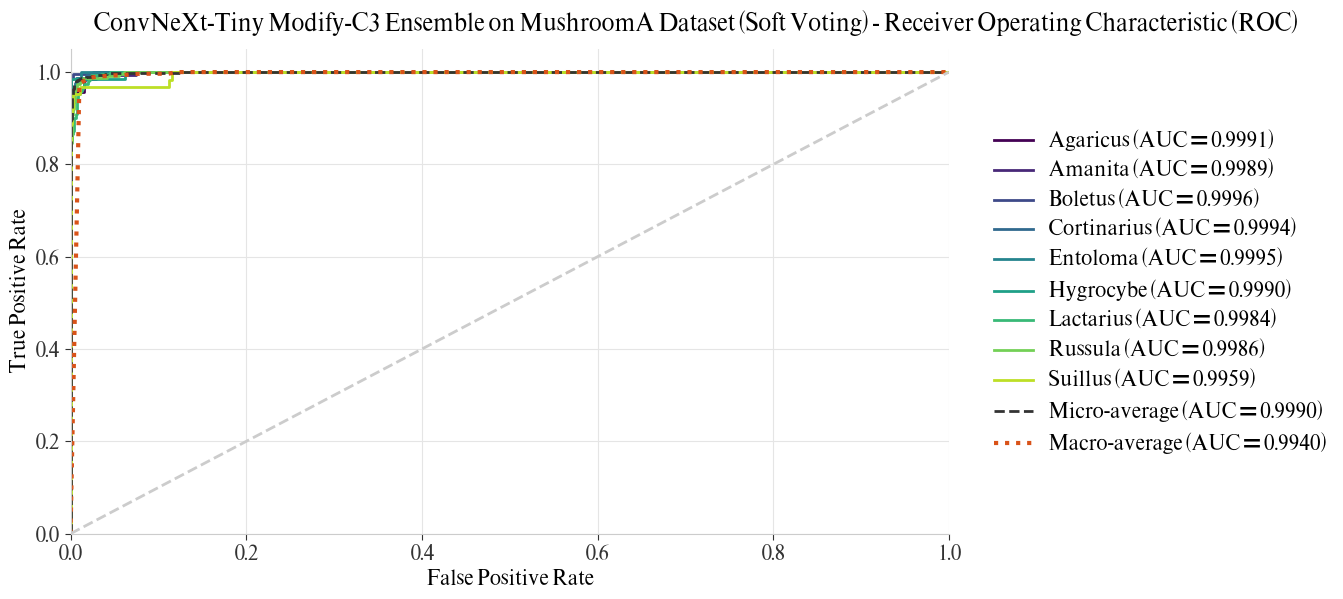




Voting Method: HARD
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/ensemble_addition/hard/hard_test_perf_best_weight.csv
              precision    recall  f1-score   support

    Agaricus     0.9710    0.9571    0.9640        70
     Amanita     0.9664    0.9600    0.9632       150
     Boletus     0.9906    0.9906    0.9906       213
 Cortinarius     0.9641    0.9641    0.9641       167
    Entoloma     0.9855    0.9315    0.9577        73
   Hygrocybe     0.9841    0.9841    0.9841        63
   Lactarius     0.9452    0.9767    0.9607       300
     Russula     0.9688    0.9518    0.9602       228
     Suillus     0.9516    0.9516    0.9516        62

    accuracy                         0.9668      1326
   macro avg     0.9697    0.9631    0.9662      1326
weighted avg     0.9670    0.9668    0.9668      1326



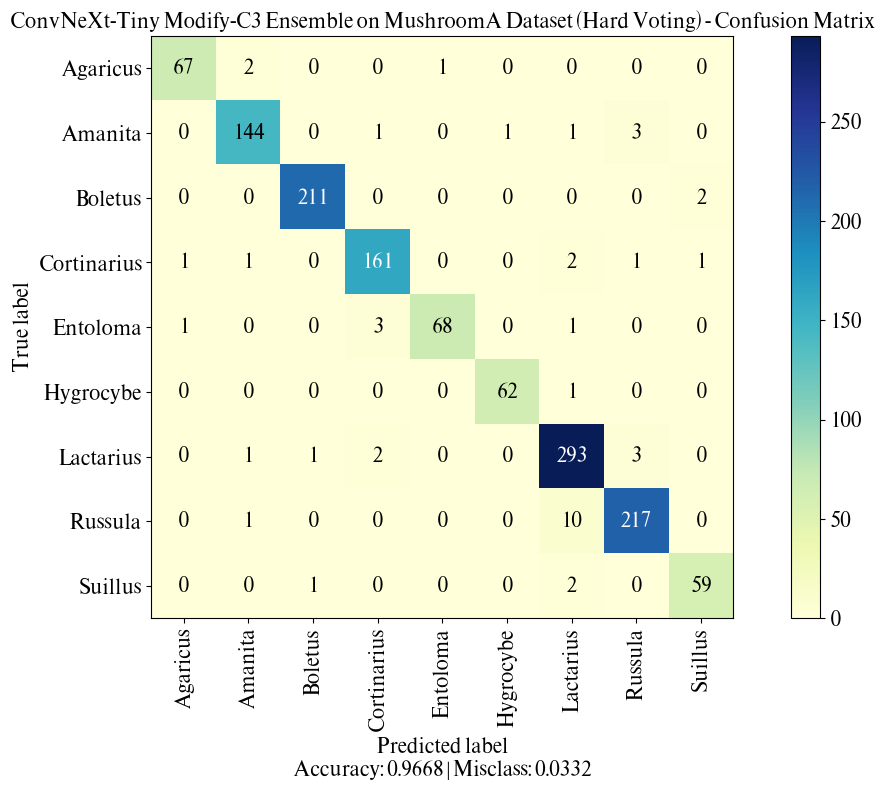

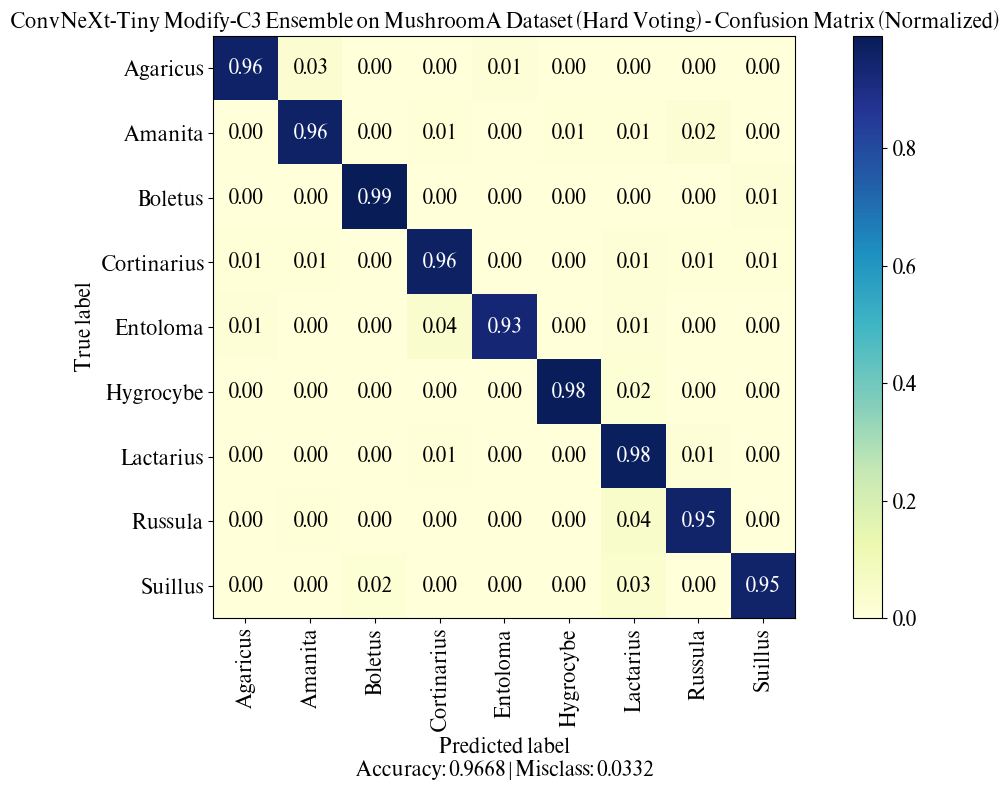




Voting Method: WEIGHTED
[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/ensemble_addition/weighted/weighted_test_perf_best_weight.csv
              precision    recall  f1-score   support

    Agaricus     0.9571    0.9571    0.9571        70
     Amanita     0.9728    0.9533    0.9630       150
     Boletus     0.9860    0.9906    0.9883       213
 Cortinarius     0.9701    0.9701    0.9701       167
    Entoloma     0.9855    0.9315    0.9577        73
   Hygrocybe     0.9841    0.9841    0.9841        63
   Lactarius     0.9484    0.9800    0.9639       300
     Russula     0.9733    0.9605    0.9669       228
     Suillus     0.9508    0.9355    0.9431        62

    accuracy                         0.9683      1326
   macro avg     0.9698    0.9625    0.9660      1326
weighted avg     0.9685    0.9683    0.9683      1326



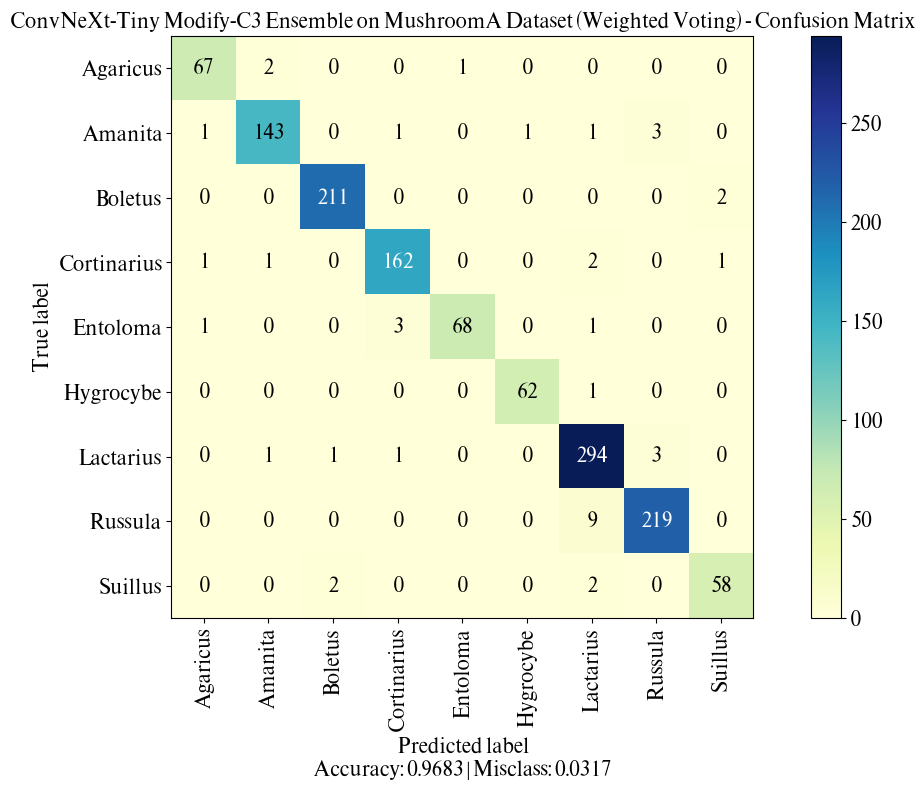

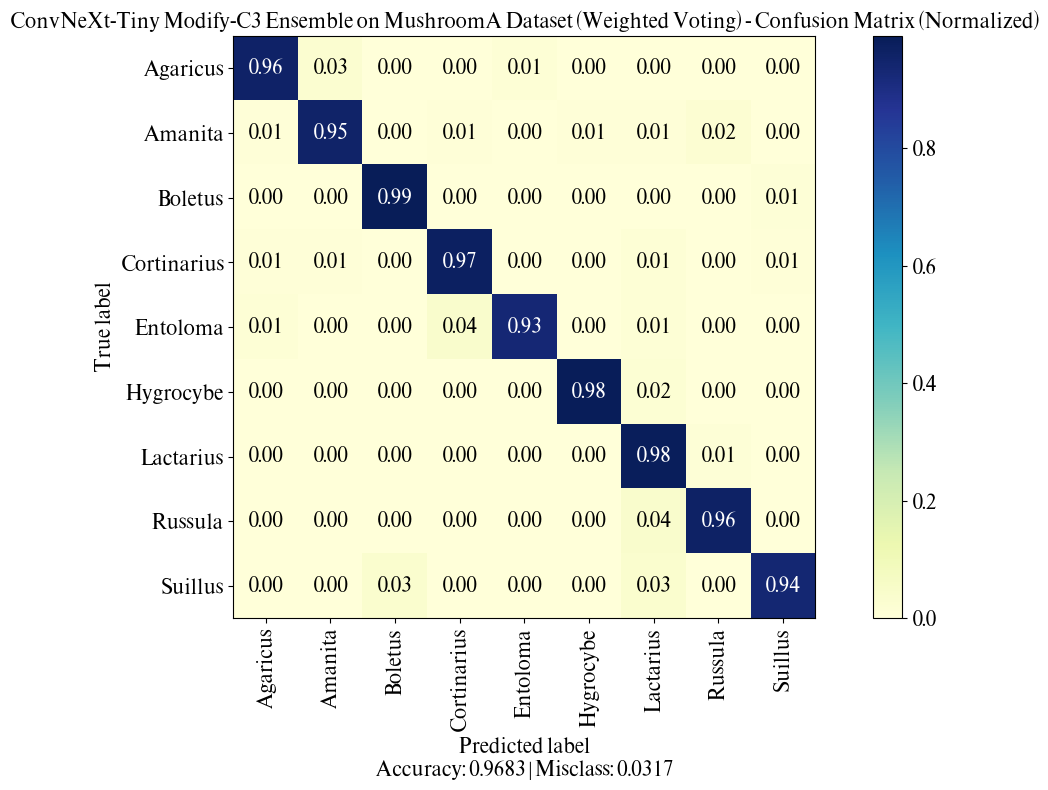

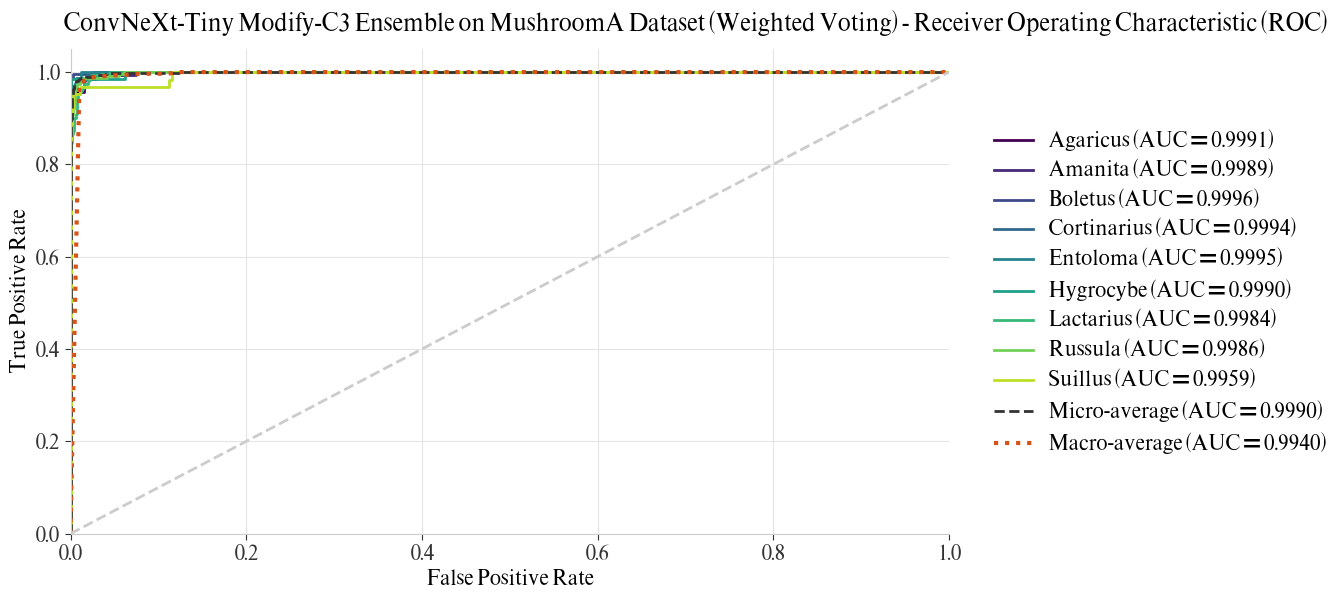




----------------------------------------------------------------------------------------------------
Ensemble Voting Comparison on Test Set (5 models):
         Method     loss  accuracy       f1  precision   recall  n_models  Aggregation Latency (ms/img)  Inference Latency (ms/img)  Total Latency (ms/img)
    Soft Voting 0.110426  0.968326 0.966027   0.969794 0.962532         5                      0.000044                    9.275513                9.275557
    Hard Voting      NaN  0.966817 0.966249   0.969700 0.963055         5                      0.000249                    9.275513                9.275762
Weighted Voting 0.110419  0.968326 0.966027   0.969794 0.962532         5                      0.000094                    9.275513                9.275607
----------------------------------------------------------------------------------------------------
[Logs] Saved Voting Comparison to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_

In [4]:
voting_comparison_df, voting_results = ensembleVoting.compare_voting_strategies(
    base_dir=add_model_dir,
    n_splits=add_config['n_folds'],
    weight_type=add_config['weight_type'],
    task=add_config['task'],
    average=add_config['average'],
    title=f'{add_model_name} Ensemble on {add_dataset_name} Dataset',
    cm_figsize=(12, 8),
    roc_figsize=(14, 6),
    **add_plot_kwargs,
)

##### **Voting weights (from validation accuracy)**

In [5]:
voting_weights_df = pd.read_csv(f"{add_model_dir}/ensemble_addition/voting_weights_{add_config['weight_type']}_weight.csv")
display(voting_weights_df.style.hide(axis="index"))

Fold,val_accuracy,weight
Fold 1,0.961357,0.199848
Fold 2,0.967012,0.201023
Fold 3,0.963208,0.200233
Fold 4,0.960377,0.199644
Fold 5,0.958491,0.199252


##### **Performance on Test Set (Voting comparison, latency in ms/img)**

In [6]:
display(voting_comparison_df.style.hide(axis="index"))

Method,loss,accuracy,f1,precision,recall,n_models,Aggregation Latency (ms/img),Inference Latency (ms/img),Total Latency (ms/img)
Soft Voting,0.110426,0.968326,0.966027,0.969794,0.962532,5,0.000044,9.275513,9.275557
Hard Voting,nan,0.966817,0.966249,0.969700,0.963055,5,0.000249,9.275513,9.275762
Weighted Voting,0.110419,0.968326,0.966027,0.969794,0.962532,5,0.000094,9.275513,9.275607


##### **McNemar's test (Baseline vs Proposed)**

ConvNeXt-T vs Modify

[*] Loaded 1326 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomA/convnext_tiny_224_r1_v1_MushroomA/ensemble
[*] Loaded 1326 predictions from /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomA/convnext_tiny_modify_C3_224_r1_v1_MushroomA/ensemble
[*] Aligned 1326 test samples (Filepaths and true labels verified)

----------------------------------------------------------------------------------------------------
McNemar's Test: ConvNeXt-Tiny Modify-C3 vs ConvNeXt-Tiny (N = 1326)
                                   ConvNeXt-Tiny Correct  ConvNeXt-Tiny Incorrect
ConvNeXt-Tiny Modify-C3 Correct                     1278                        6
ConvNeXt-Tiny Modify-C3 Incorrect                      8                       34

Chi-square = 0.0714 | p-value = 0.7893 | Exact p-value = 0.7905
alpha = 0.05 -> Fail to reject H0 (no significant difference)
----------------------------------------------------------------------------------------------------
[

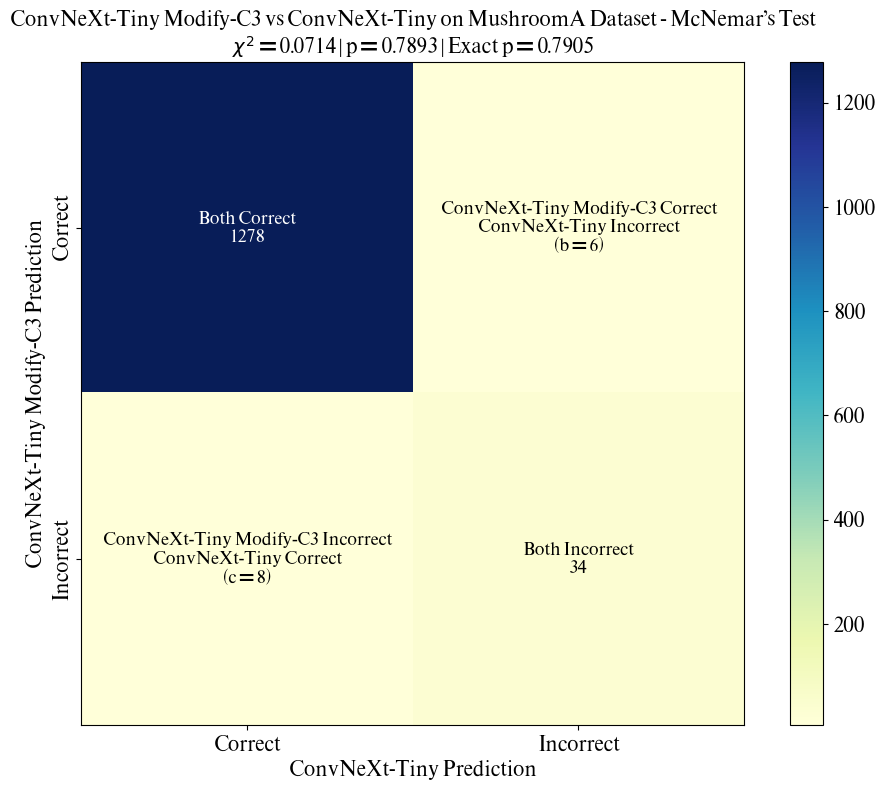

In [7]:
mcnemar_result_df, mcnemar_aligned_df = mcnemarTest.compare_mcnemar(
    baseline_model_dir=mc_baseline_model_dir,
    proposed_model_dir=mc_proposed_model_dir,
    baseline_name=mc_baseline_name,
    proposed_name=mc_proposed_name,
    alpha=mc_alpha,
    title=f'{mc_proposed_name} vs {mc_baseline_name} on {add_dataset_name} Dataset',
    figsize=(10, 8),
    **add_plot_kwargs,
)

##### **McNemar's test result**

In [8]:
display(mcnemar_result_df.style.hide(axis="index"))

Baseline,Proposed,N,Baseline Accuracy,Proposed Accuracy,Accuracy Diff (pp),Both Correct,"b (Proposed Correct, Baseline Incorrect)","c (Proposed Incorrect, Baseline Correct)",Both Incorrect,Chi-square,p-value,Exact p-value,Alpha,Significant
ConvNeXt-Tiny,ConvNeXt-Tiny Modify-C3,1326,0.969834,0.968326,-0.150830,1278,6,8,34,0.071429,0.789268,0.790527,0.050000,False


##### **Disagreement samples (Only one model is correct)**

In [9]:
mcnemar_aligned_df[mcnemar_aligned_df['Baseline_Correct'] != mcnemar_aligned_df['Proposed_Correct']]

,Filepaths,True_Index,True_Label,Baseline_Pred_Index,Baseline_Pred_Label,Proposed_Pred_Index,Proposed_Pred_Label,Baseline_Correct,Proposed_Correct
218,/content/MushroomA/test/Amanita/770_052Nt-FjZI...,1,Amanita,1,Amanita,3,Cortinarius,True,False
579,/content/MushroomA/test/Cortinarius/850_3-IUA4...,3,Cortinarius,6,Lactarius,3,Cortinarius,False,True
648,/content/MushroomA/test/Entoloma/272_X7hdxfwoE...,4,Entoloma,4,Entoloma,3,Cortinarius,True,False
671,/content/MushroomA/test/Entoloma/397_xs0CzcF5E...,4,Entoloma,4,Entoloma,6,Lactarius,True,False
744,/content/MushroomA/test/Lactarius/0026_autPTj6...,6,Lactarius,7,Russula,6,Lactarius,False,True
757,/content/MushroomA/test/Lactarius/0101_GFyNRQO...,6,Lactarius,4,Entoloma,6,Lactarius,False,True
922,/content/MushroomA/test/Lactarius/0907_osHGPvS...,6,Lactarius,6,Lactarius,7,Russula,True,False
942,/content/MushroomA/test/Lactarius/104_oXM-6Kpp...,6,Lactarius,7,Russula,6,Lactarius,False,True
1020,/content/MushroomA/test/Lactarius/344_1Qlt5YMK...,6,Lactarius,6,Lactarius,3,Cortinarius,True,False
1127,/content/MushroomA/test/Russula/296_GgxGUQ7qmD...,7,Russula,7,Russula,6,Lactarius,True,False
